In [1]:
#Iris Flower Classification
#CodeAlpha Data Science Internship Task 1

In [2]:
# Importing required libraries
# For data manipulation and analysis
import pandas as pd
# For numerical operations
import numpy as np
# For statistical data visualization
import seaborn as sns
# For creating plots and visualizations
import matplotlib.pyplot as plt
# For splitting data into training and testing sets  
from sklearn.model_selection import train_test_split
# For logistic regression model
from sklearn.linear_model import LogisticRegression
# For model evaluation metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  
sns.set(style="white", color_codes=True)
import warnings # current version of seaborn generates a bunch of warnings that we'll ignore
warnings.filterwarnings("ignore")

In [3]:
# Import pandas library with the standard alias 'pd' for data manipulation
import pandas as pd
# Load the iris dataset into the 'iris' variable
# This dataset contains measurements of iris flowers and their species classification
df_flower=pd.read_csv("Iris.csv")
# Display the first 5 rows of the DataFrame to inspect the data
df_flower.head()

,Unnamed: 0,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
#checking dataset structure/inspecting data
df_flower.describe()

,Unnamed: 0,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,74.500000,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,43.445368,0.828066,0.433594,1.764420,0.763161
min,0.000000,1.000000,4.300000,2.000000,1.000000,0.100000
25%,37.250000,38.250000,5.100000,2.800000,1.600000,0.300000
50%,74.500000,75.500000,5.800000,3.000000,4.350000,1.300000
75%,111.750000,112.750000,6.400000,3.300000,5.100000,1.800000
max,149.000000,150.000000,7.900000,4.400000,6.900000,2.500000


In [5]:
# Display concise summary of the DataFrame 
df_flower.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     150 non-null    int64  
 1   Id             150 non-null    int64  
 2   SepalLengthCm  150 non-null    float64
 3   SepalWidthCm   150 non-null    float64
 4   PetalLengthCm  150 non-null    float64
 5   PetalWidthCm   150 non-null    float64
 6   Species        150 non-null    object 
dtypes: float64(4), int64(2), object(1)
memory usage: 8.3+ KB


In [6]:
# Checking for missing values in the dataframe
# This code calculates the sum of null values for each column
df_flower.isnull().sum()

Unnamed: 0       0
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [7]:
# Checking the distribution of species in the dataset
# This counts how many samples belong to each unique species category
df_flower["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

<Axes: xlabel='PetalLengthCm', ylabel='PetalWidthCm'>

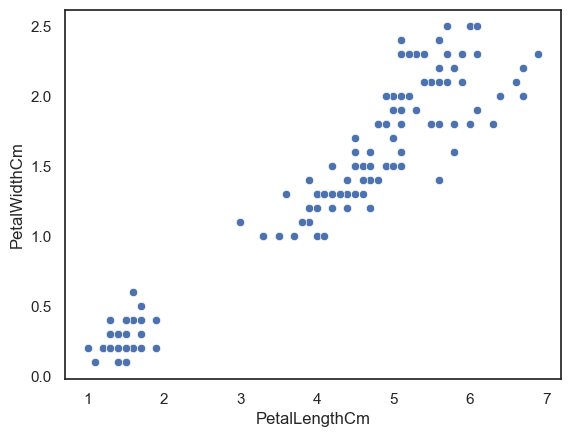

In [8]:
# Create a scatter plot to visualize the relationship 
# between petal length and width (cm) in the dataset
sns.scatterplot(x="PetalLengthCm",y="PetalWidthCm",data=df_flower)

<Axes: xlabel='SepalLengthCm', ylabel='SepalWidthCm'>

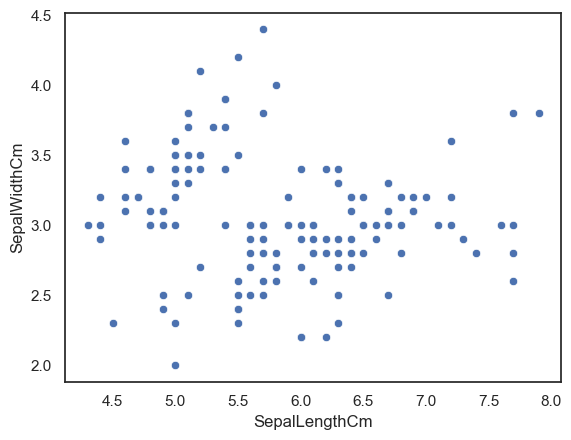

In [9]:
#relationship between sepal length and width (cm)
sns.scatterplot(x="SepalLengthCm",y="SepalWidthCm",data=df_flower)

Index(['Unnamed: 0', 'Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm',
       'PetalWidthCm', 'Species'],
      dtype='object')


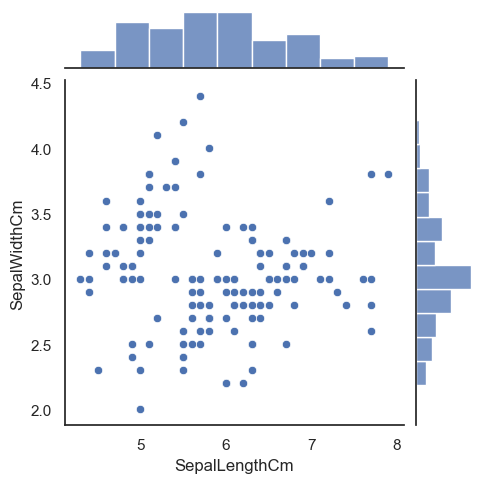

In [10]:
import seaborn as sns
import pandas as pd
# Check the actual column names in the dataset
print(df_flower.columns)
# Use the correct column names from the iris dataset
# Note: In newer versions of seaborn, 'size' parameter is replaced with 'height'
sns.jointplot(x="SepalLengthCm", y="SepalWidthCm", data=df_flower, height=5)
plt.savefig("results/figures/JointGrid.png", dpi=300, bbox_inches="tight")

Index(['Unnamed: 0', 'Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm',
       'PetalWidthCm', 'Species'],
      dtype='object')


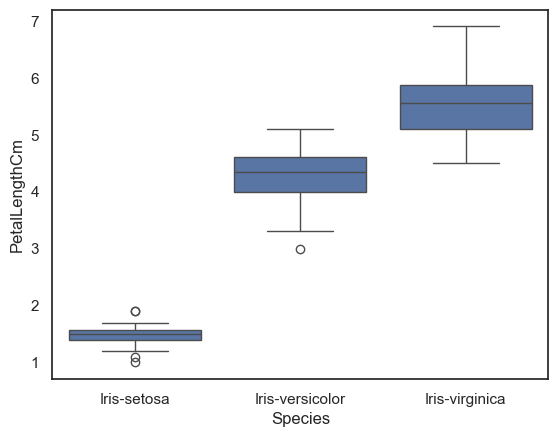

In [11]:
# First, let's check the actual column names in the iris dataset
print(df_flower.columns)
# looking at individual feature in seaborn
# Then use the correct column name in the boxplot
sns.boxplot(x="Species", y="PetalLengthCm", data=df_flower)
plt.savefig("results/figures/visualising individual feature in seaborn using boxplot.png", dpi=300, bbox_inches="tight")

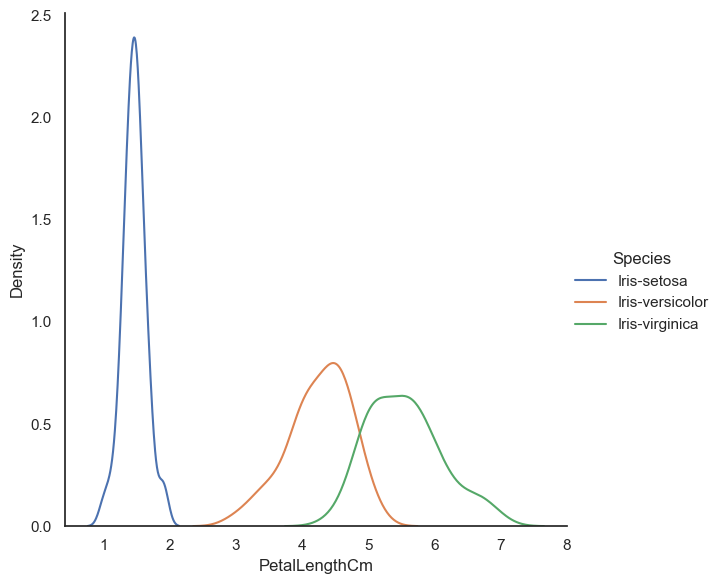

In [12]:
# Import necessary library
import seaborn as sns
# Create the plot with the correct column name
sns.FacetGrid(df_flower,hue="Species", height=6) \
   .map(sns.kdeplot, "PetalLengthCm") \
   .add_legend()
plt.savefig("results/figures/visualising petal_Length using seaborn.png", dpi=300, bbox_inches="tight")

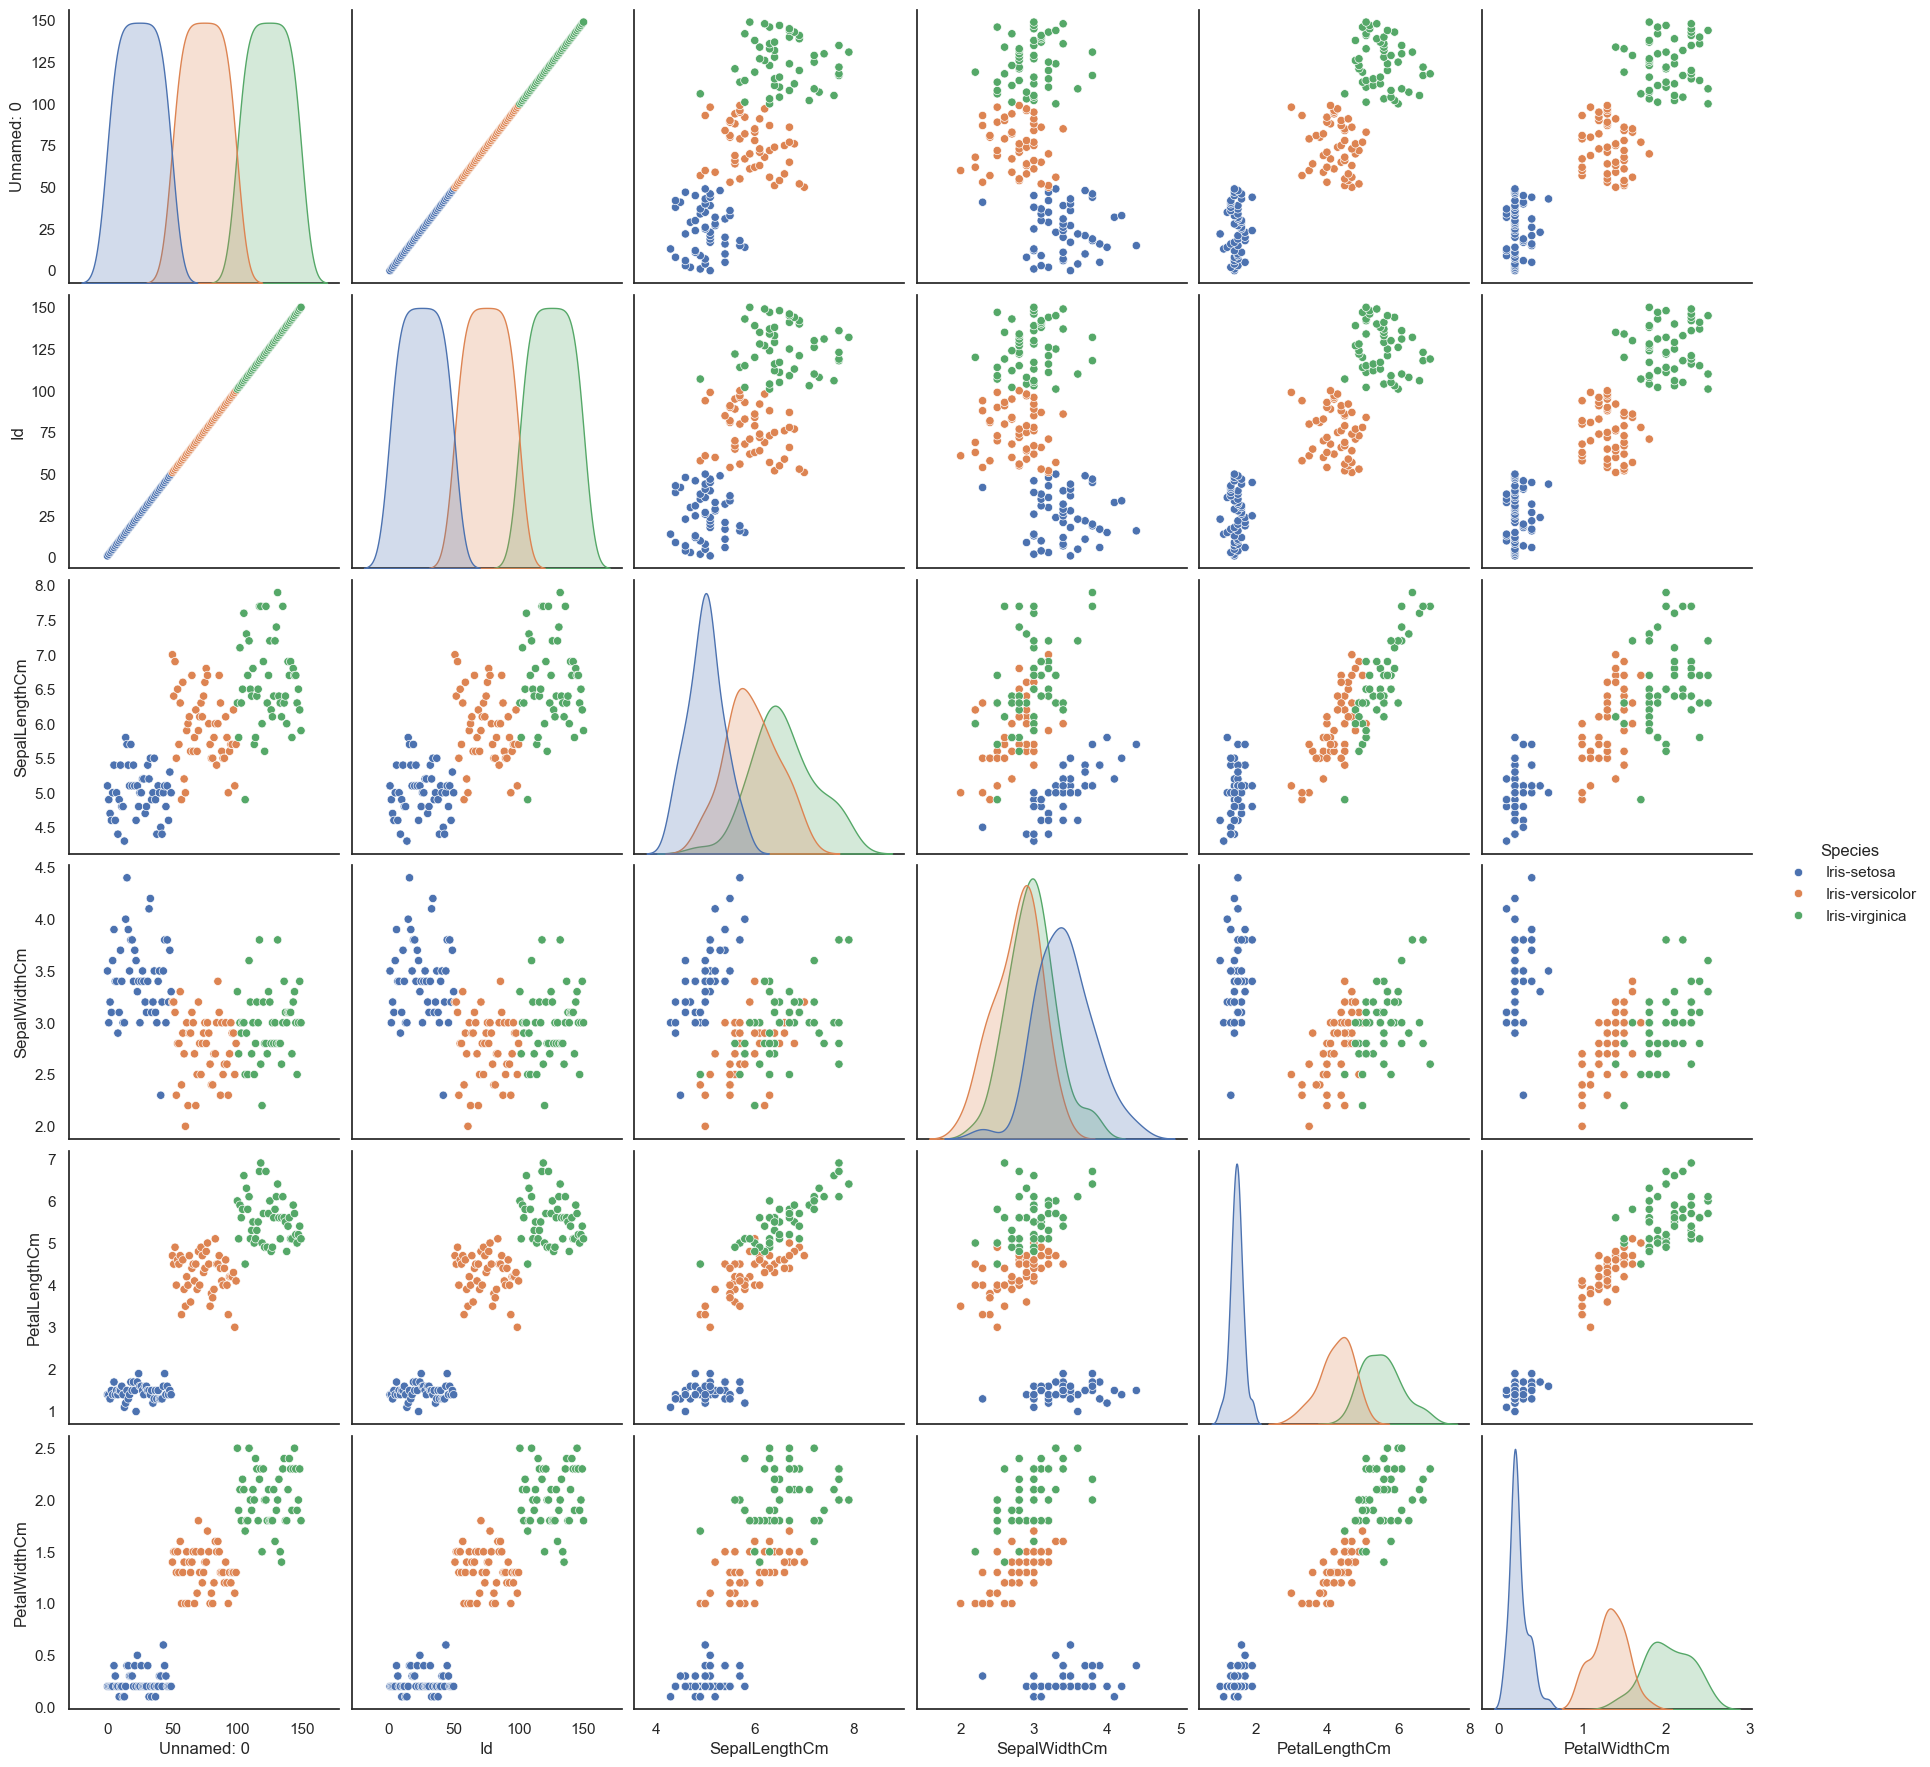

In [13]:
# Exploratory data analysis
# Visualizing relationships between features using seaborn's pairplot
# This creates a grid of scatterplots showing pairwise relationships between variables
import seaborn as sns
import matplotlib.pyplot as plt
# Create pairplot with different colors for each species
# The 'hue' parameter colors points by species category
sns.pairplot(df_flower, hue="Species",height=3)
# Save the visualization as a high-resolution PNG file
# dpi=300 sets high resolution, bbox_inches="tight" removes extra whitespace
plt.savefig("results/figures/visualising relationships using seaborn.png", dpi=300, bbox_inches="tight")
# Display the plot in the notebook
plt.show()

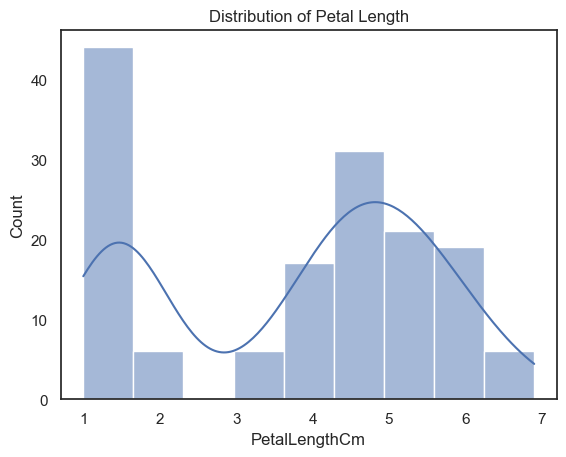

In [14]:
# Create a histogram with kernel density estimate to visualize the distribution of petal lengths
sns.histplot(df_flower["PetalLengthCm"], kde=True)
# Add a title to the plot
plt.title("Distribution of Petal Length")
# Save the figure to the specified path with high resolution (300 dpi) and tight layout
plt.savefig("results/figures/distribution of petal length.png", dpi=300, bbox_inches="tight")
# Display the plot
plt.show()

In [15]:
# Preparing data for modelling
# Splitting into training and testing sets
from sklearn.model_selection import train_test_split
# Separate features (X) and target variable (y)
# Features: all columns except 'species'
X = df_flower.drop("Species", axis=1)
# Target: the 'species' column
y = df_flower["Species"]              
# Split data into training (80%) and testing (20%) sets
# random_state=42 ensures reproducibility of the split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
# Import the Logistic Regression model from scikit-learn
from sklearn.linear_model import LogisticRegression
# Initialize the logistic regression model with increased max iterations
# This helps ensure convergence for complex datasets
model = LogisticRegression(max_iter=200,random_state=42)
# Train the model using the training data
# X_train contains the features, y_train contains the target labels
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [17]:
# Making predictions using the trained model on the test data
# This will generate predicted values that we can compare with actual values
y_pred=model.predict(X_test)

In [18]:
# Import accuracy_score function from sklearn.metrics to evaluate model performance
from sklearn.metrics import accuracy_score
# Calculate accuracy by comparing predicted values (y_pred) with actual test values (y_test)
accuracy=accuracy_score(y_test,y_pred)
# Print the accuracy score as a percentage of correct predictions
print("Model Accuracy:",accuracy)

Model Accuracy: 1.0


In [19]:
# Import confusion_matrix function from sklearn.metrics module to evaluate classification results
from sklearn.metrics import confusion_matrix
# Create a confusion matrix by comparing the actual test labels (y_test) with predicted labels (y_pred)
# The confusion matrix shows true positives, false positives, true negatives, and false negatives
coma = confusion_matrix(y_test, y_pred)
# Display the confusion matrix to evaluate the model's performance
print(coma)

[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [20]:
# Print a detailed classification report showing precision, recall, f1-score, and support
# for each species separately. This helps evaluate model performance across all classes.
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



In [21]:
# Import the RandomForest classifier from scikit-learn
from sklearn.ensemble import RandomForestClassifier 
# Initialize a RandomForest classifier with default parameters
model = RandomForestClassifier(random_state=42)
# Train the model using the training data
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [22]:
#making predictions
y_pred=model.predict(X_test)

In [23]:
#model evaluation,accuracy
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)
print("Model Accuracy:",accuracy)

Model Accuracy: 1.0


In [24]:
#checking confusion matrix
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [25]:
# Perform cross-validation to evaluate model performance
# Import cross_val_score function and KFold function from sklearn's model_selection module
from sklearn.model_selection import KFold
# controlling the cross validation splits
kf=KFold(n_splits=5,shuffle=True,random_state=42)
from sklearn.model_selection import cross_val_score
# Calculate cross-validation scores using 5 folds
# This evaluates how well the model performs on different subsets of the data
scores = cross_val_score(model, X, y, cv=kf)
# This gives us the average performance across all folds
print(scores.mean())

0.9933333333333334


In [26]:
#showing performance for each species separatly
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



In [27]:
#defining models
from sklearn.tree import DecisionTreeClassifier
models={"Logistic Regression":LogisticRegression(max_iter=200,random_state=42),"Decision Tree":DecisionTreeClassifier(random_state=42),
      "Random Forest":RandomForestClassifier(random_state=42)}

In [28]:
# Running 5-fold cross-validation for each model
for name,model in models.items():
    scores=cross_val_score(model,X,y,cv=kf)
print(name)
print("Accuracy Scores:",scores)
print("Mean Accuracy:",scores.mean())
print("Standard Deviation:",scores.std())
print()

Random Forest
Accuracy Scores: [1.         1.         1.         0.96666667 1.        ]
Mean Accuracy: 0.9933333333333334
Standard Deviation: 0.01333333333333333



In [29]:
results=[]
for name,model in models.items():
    scores=cross_val_score(model,X,y,cv=kf)
    results.append({"Model":name,"Mean Accuracy":scores.mean(),"Std Dev":scores.std()})
df_results=pd.DataFrame(results)
print(df_results)

                 Model  Mean Accuracy   Std Dev
0  Logistic Regression       1.000000  0.000000
1        Decision Tree       0.993333  0.013333
2        Random Forest       0.993333  0.013333


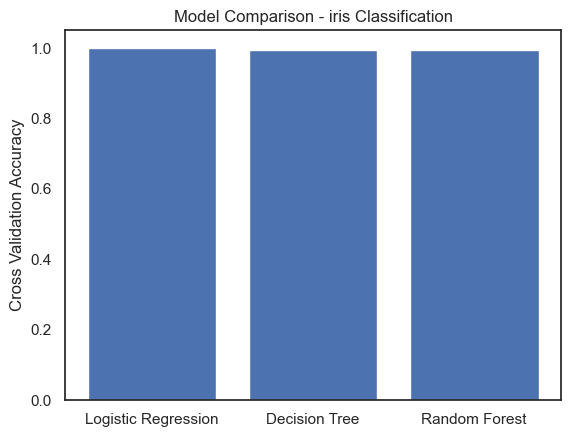

In [30]:
plt.bar(df_results["Model"],df_results["Mean Accuracy"])
plt.ylabel("Cross Validation Accuracy")
plt.title("Model Comparison - iris Classification")
plt.savefig("results/figures/Model Comparison - iris Classification.png", dpi=300, bbox_inches="tight")
plt.show()